# Exploratory Data Analysis
Before training any model, we look at the data: how many images, how many per style, what they look like, and how they are split.


In [1]:
import os
os.chdir("..")                      # run from the repo root, where data/ and splits/ are

import matplotlib.pyplot as plt
import pandas as pd
import torch

from museum_guide.data import load_images

In [2]:
X, y, meta = load_images()
CLASSES = sorted(meta["label"].unique())
print("images:", tuple(X.shape), "| labels:", tuple(y.shape))
print("pixel values between", X.min().item(), "and", X.max().item())

images: (1500, 3, 128, 128) | labels: (1500,)
pixel values between 0.0 and 1.0


In [3]:
for k, name in enumerate(CLASSES):
    print(f"{name:15s} {torch.bincount(y)[k].item()} images")

Baroque         300 images
Cubism          300 images
Impressionism   300 images
Pop_Art         300 images
Ukiyo_e         300 images


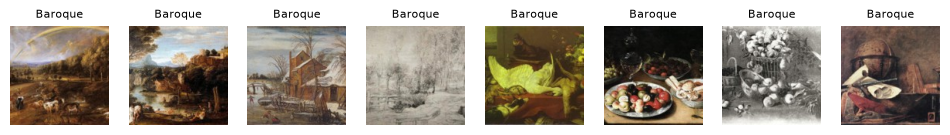

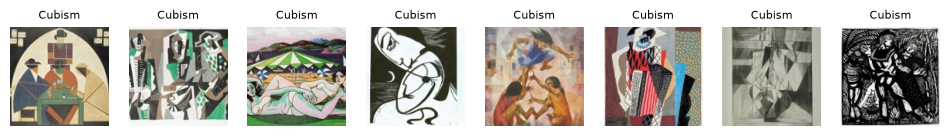

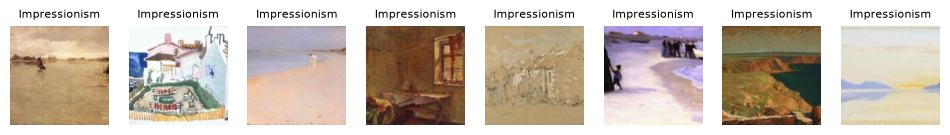

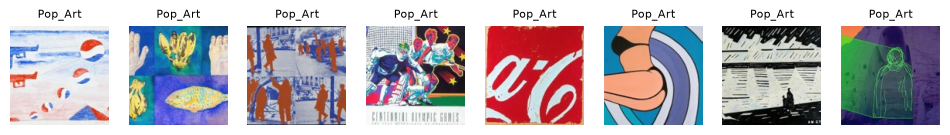

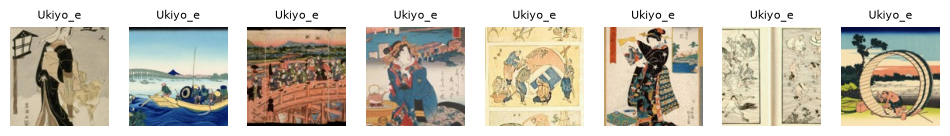

In [4]:
def show_images(images, titles, n=10):
    fig, axes = plt.subplots(1, n, figsize=(1.5 * n, 1.9))
    for ax, img, title in zip(axes, images[:n], titles[:n]):
        ax.imshow(img.permute(1, 2, 0))          # (3, 128, 128) -> (128, 128, 3) for a colour image
        ax.set_title(title, fontsize=8)
        ax.axis("off")
    plt.show()


for k, name in enumerate(CLASSES):
    show_images(X[y == k], [name] * 8, n=8)

In [5]:
split = pd.read_csv("splits/split.csv")
print(pd.crosstab(meta["label"], split["split"]))

split          test  train  val
label                          
Baroque          52    197   51
Cubism           53    204   43
Impressionism    57    188   55
Pop_Art          52    191   57
Ukiyo_e          36    220   44


## Conclusion
- 1 500 images, 5 styles, 300 per style: the classes are balanced.
- Colour images of 128 x 128 pixels, values in [0, 1].
- Split 1000 / 250 / 250 grouped by artist: a painter is never on two sides.